In [1]:
%load_ext autoreload
%autoreload 2
%aimport -fiftyone

from detection_common import configure_stdio_relative_path

from dataset_builder.config import WORKSPACE_ROOT

# Display project paths relatively for consistent output across environments.
configure_stdio_relative_path(WORKSPACE_ROOT)

In [2]:
from collections import defaultdict
from typing import cast

import fiftyone as fo

MASTER_DATASET = "sports_objects_master"

# Dataset Deduplication

1. **Exact-duplicate detection**. Select one representative per exact group for
subsequent analysis.
2. **Compute and cache a separate perceptual_hash field**. Compare hashes using
Hamming distance, then display candidate pairs or groups for review.
3. **Run embedding-based detection on those same exact-group representatives**. Keep
   unconfirmed perceptual matches in this search; they may help reveal additional
   relationships.
4. **Record each method separately**, for example with `review:perceptual_duplicate`
and `review:embedding_duplicate` tags. Show references alongside candidates and retain
all samples during review.

Tag exact pixel duplicates using the `pixel_digest` field cached during import.
This does not detect pixel changes introduced by lossy recompression.

## 1. Load the master sport object detection dataset

The "sports_objects_master" should have been created by `nb01.07.01`.

In [3]:
import logging

logging.getLogger("fiftyone.core.config").setLevel(logging.ERROR)

if not fo.dataset_exists(MASTER_DATASET):
    raise ValueError(f"Dataset {MASTER_DATASET!r} not found. Run nb01.07.01 first.")

master = fo.load_dataset(MASTER_DATASET)
master.persistent = True
if not master.has_sample_field("pixel_digest"):
    raise ValueError("Run nb01.07.01 to populate the pixel_digest field first.")

## 2. Detecting exact duplicates (image pixel hash)

### 2.1 Tag exact pixel duplicates for review

Group the stored digests without reopening images. Keep the first sample in
each group untagged and tag the remaining copies. Refresh this review tag on
reruns. This includes byte-identical files and other encodings with identical
normalized pixels. Samples and media files are retained for review.

In [4]:
# FiftyOne's inferred aggregation type does not describe this two-field result.
sample_ids, pixel_digests = cast(
    tuple[list[str], list[str | None]],
    master.values(["id", "pixel_digest"]),
)
if any(not digest for digest in pixel_digests):
    raise ValueError("Every sample must have a pixel_digest before tagging.")

ids_by_digest = defaultdict(list)
for sample_id, digest in zip(sample_ids, pixel_digests):
    ids_by_digest[digest].append(sample_id)

duplicate_ids = [sid for ids in ids_by_digest.values() for sid in ids[1:]]
master.untag_samples("review:exact_duplicate")
if duplicate_ids:
    master.select(duplicate_ids).tag_samples("review:exact_duplicate")

dup_groups_cnt = sum(len(ids) > 1 for ids in ids_by_digest.values())
print("Exact pixel duplicate groups:", dup_groups_cnt)
print("Tagged extra copies:", len(duplicate_ids))

Exact pixel duplicate groups: 295
Tagged extra copies: 389


### 2.2 Run FiftyOne Apps for visual reviews of exact duplicates.

#### 2.2.1 Show all duplicate samples

Show all duplicate groups, including their untagged first samples. Rebuild the
selection from the digest groups so earlier reviews cannot consume it. Sort by
digest to keep matching samples adjacent in the App.


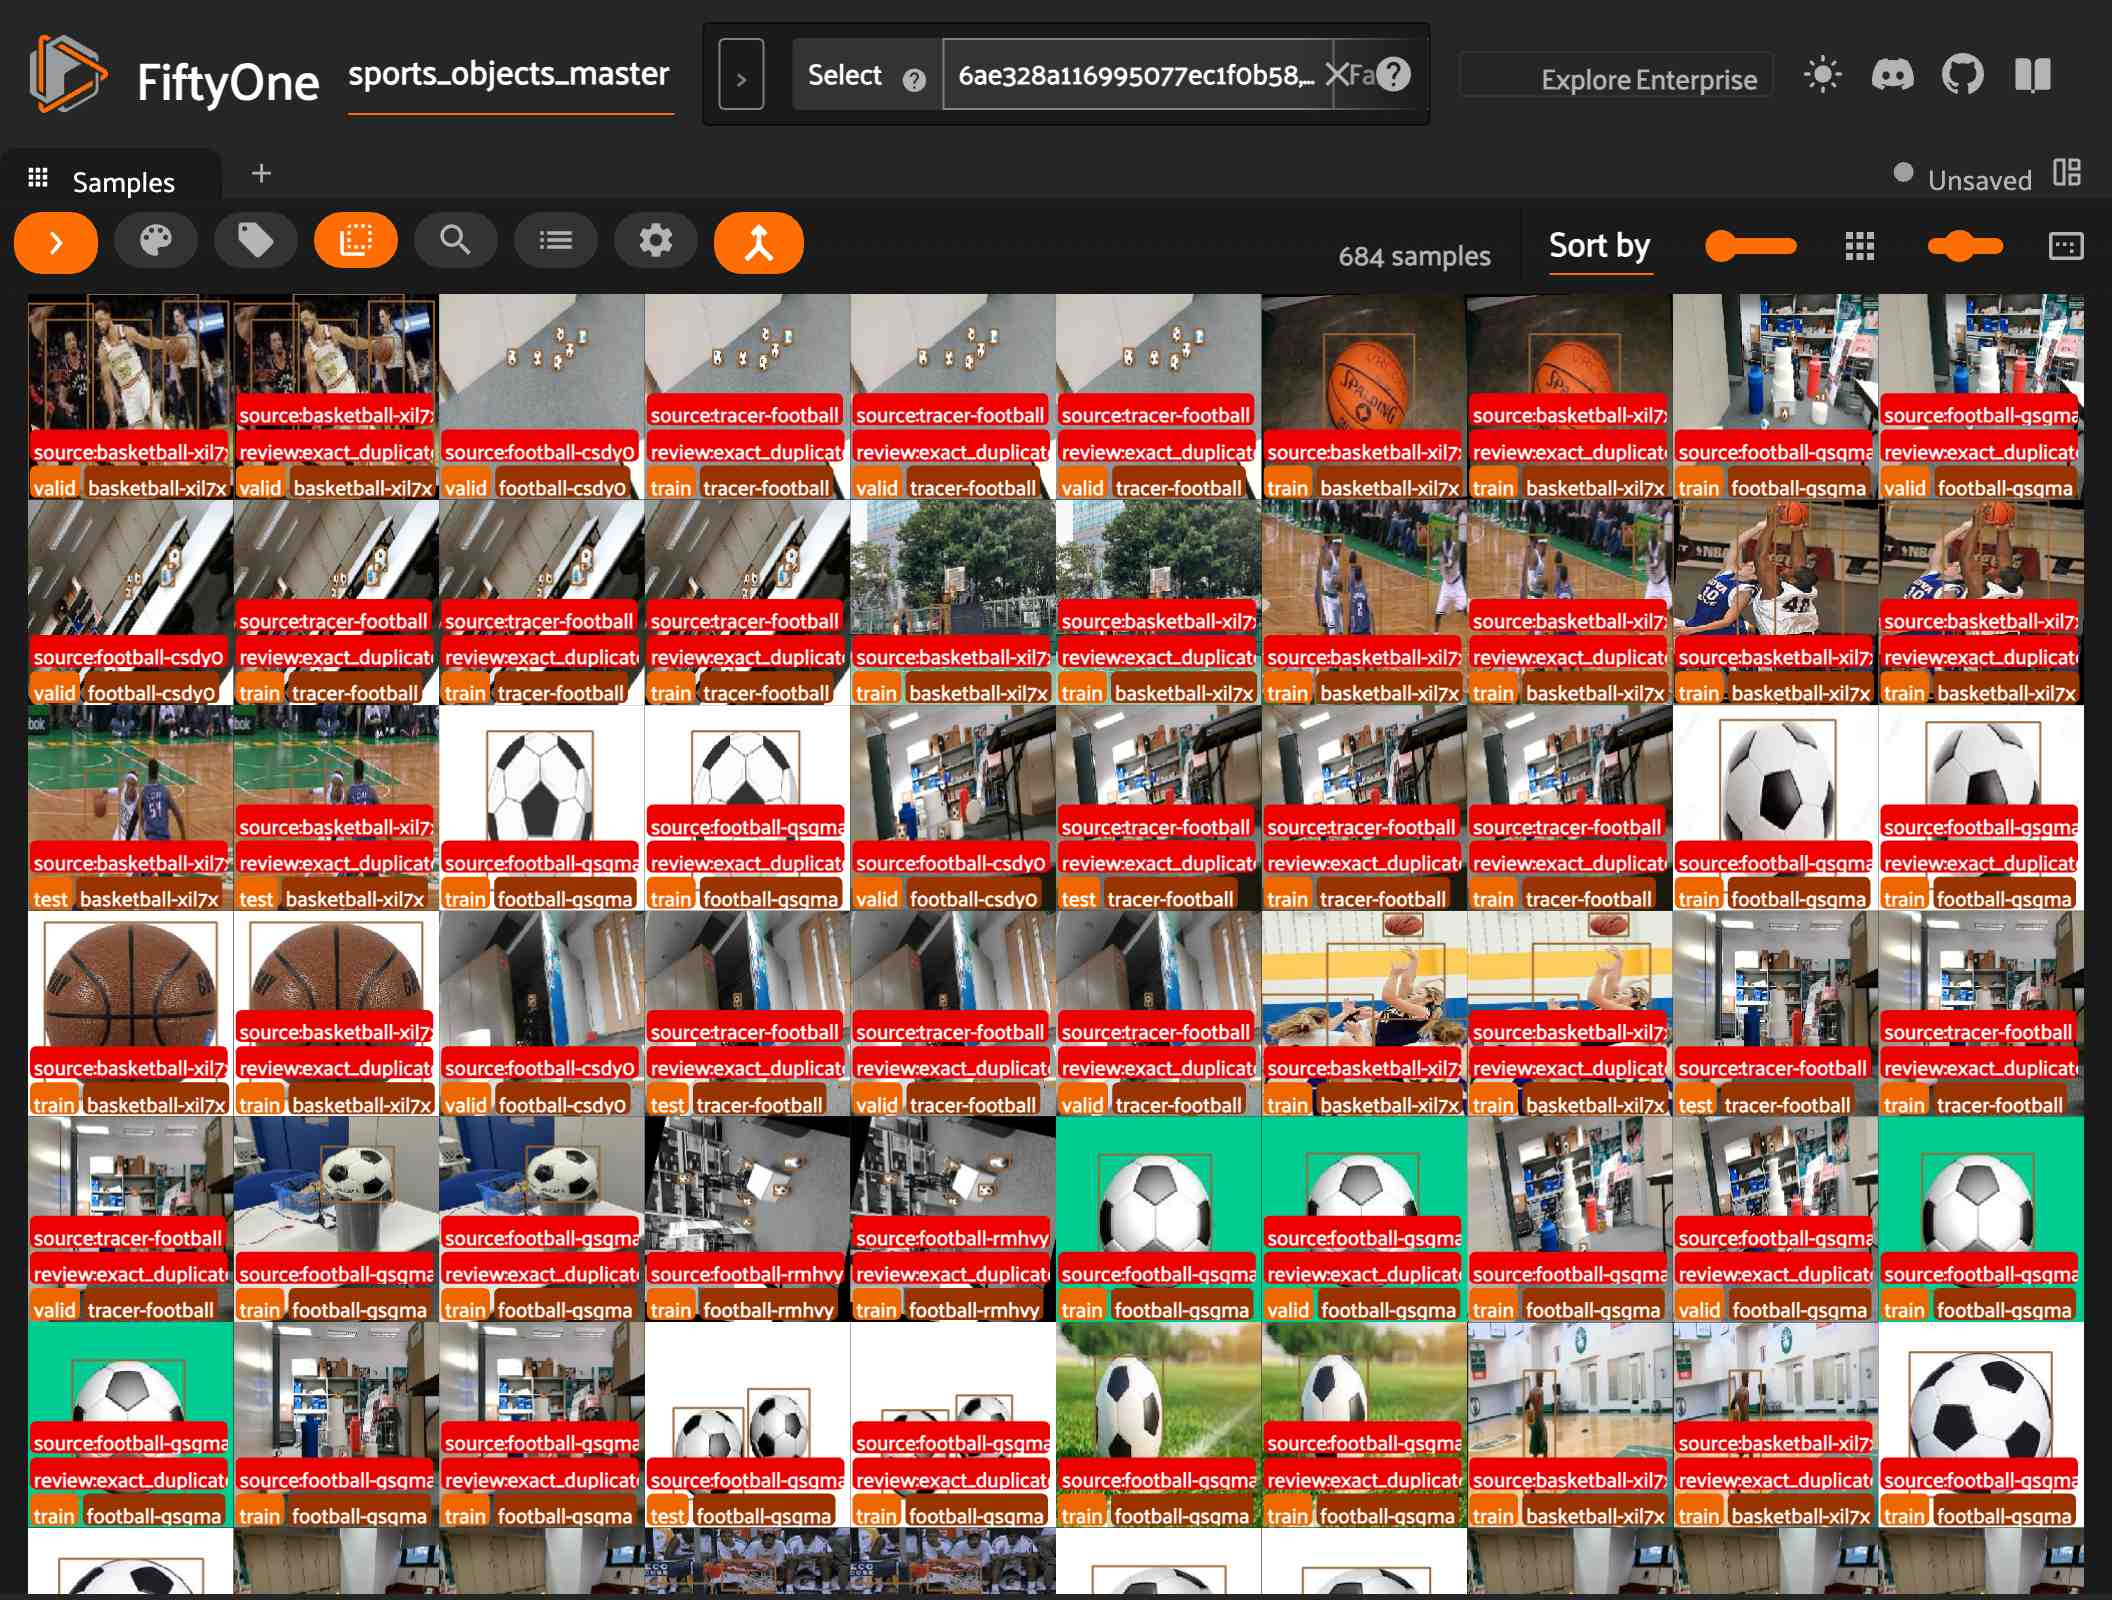

In [5]:
all_duplicate_ids = [
    sid for ids in ids_by_digest.values() if len(ids) > 1 for sid in ids
]
review_view = master.select(all_duplicate_ids).sort_by("pixel_digest")
session = fo.launch_app(view=review_view)

#### 2.2.2 Iteratively review

In [ ]:
session.freeze()
duplicate_samples = (ids for ids in ids_by_digest.values() if len(ids) > 1)

Iteratively run the following cell to do visual review on the duplicated samples:


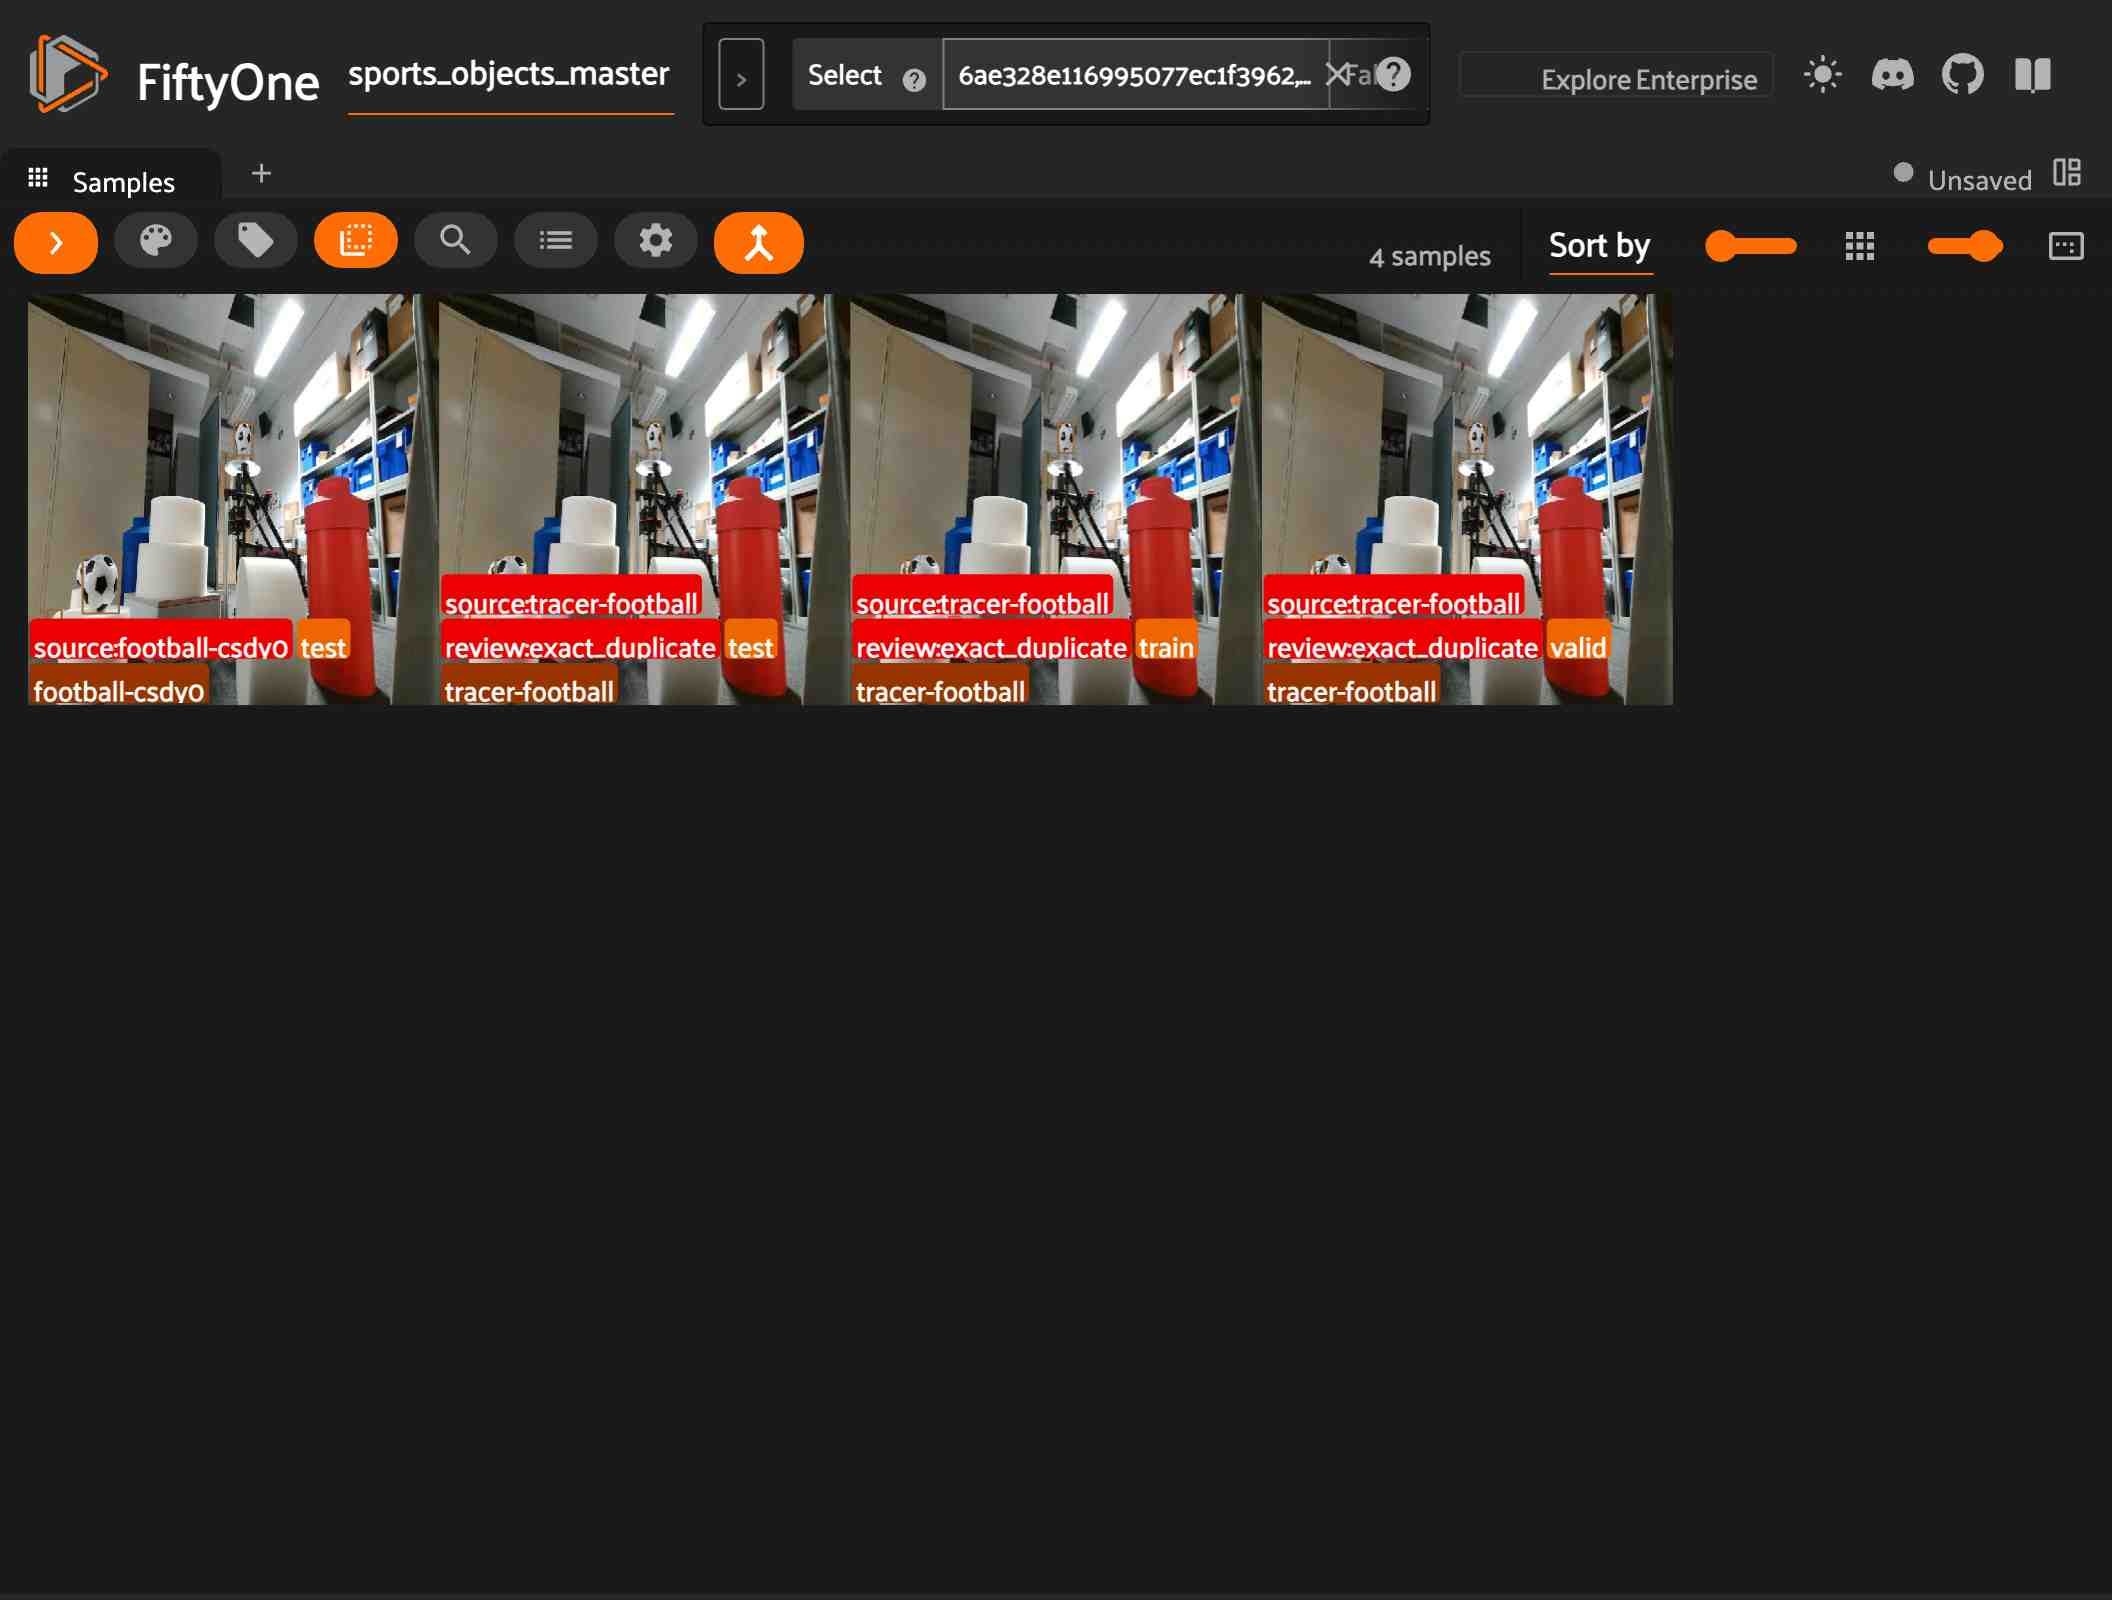

In [115]:
group_ids = next(duplicate_samples, None)
if group_ids:
    review_view = master.select(group_ids)
    session = fo.launch_app(view=review_view)

In [ ]:
session.freeze()

## 3. Detecting perceptually duplicates (perceptual hash)

### 3.1 Set up pHash

Use `imagehash.phash(image, hash_size=PHASH_SIZE)` for 256-bit fingerprints.
ImageHash hashes and compares images on CPU without a model download.

In [11]:
import imagehash

PHASH_SIZE = 16

### 3.2 Select images to compare

Keep the first sample from every pixel-digest group, including singletons.
Reuse the digest groups so changes to review tags do not affect selection.
Map each representative to its other exact copies; singletons have no copies.
This creates a view without changing samples, tags, or source images.

In [12]:
exact_copies_by_representative = {ids[0]: ids[1:] for ids in ids_by_digest.values()}
representative_ids = list(exact_copies_by_representative)
print("Images selected for comparison:", len(representative_ids))

representative_view = master.select(representative_ids, ordered=True)
exclude_cnt = sum(len(copies) for copies in exact_copies_by_representative.values())
print("Exact copies excluded from comparison:", exclude_cnt)

Images selected for comparison: 33614
Exact copies excluded from comparison: 389


### 3.3 Compute and cache perceptual hashes

Open only representatives without a cached hash. Apply EXIF orientation before
computing the 256-bit pHash, then store its hexadecimal representation in FiftyOne.
Source images and `pixel_digest` stay unchanged. Report unreadable images and
leave their hashes missing so they are excluded from the comparison view.

In [13]:
from PIL import Image, ImageOps

if not master.has_sample_field("perceptual_hash"):
    master.add_sample_field("perceptual_hash", fo.StringField)

unhashed_ids, unhashed_paths = cast(
    tuple[list[str], list[str]],
    representative_view.exists("perceptual_hash", False).values(["id", "filepath"]),
)
new_perceptual_hashes = {}
unreadable_ids = []

with fo.ProgressBar(total=len(unhashed_ids)) as progress:
    for sample_id, image_path in progress(zip(unhashed_ids, unhashed_paths)):
        try:
            with Image.open(image_path) as image:
                normalized = ImageOps.exif_transpose(image)
                new_perceptual_hashes[sample_id] = str(
                    imagehash.phash(normalized, hash_size=PHASH_SIZE)
                )
        except (OSError, ValueError, Image.DecompressionBombError) as error:
            unreadable_ids.append(sample_id)
            print(f"Skipping unreadable image {sample_id} ({image_path}): {error}")

if new_perceptual_hashes:
    master.set_values("perceptual_hash", new_perceptual_hashes, key_field="id")

hashed_representative_view = representative_view.exists("perceptual_hash")
print("Reused cached hashes:", len(representative_ids) - len(unhashed_ids))
print("Computed hashes:", len(new_perceptual_hashes))
print("Unreadable images skipped:", len(unreadable_ids))
print("Representatives ready for comparison:", hashed_representative_view.count())

 100% |█████████████| 33614/33614 [1.4m elapsed, 0s remaining, 400.2 samples/s]      
Reused cached hashes: 0
Computed hashes: 33614
Unreadable images skipped: 0
Representatives ready for comparison: 33614


### 3.4 Find candidate pairs

Compare cached hashes in batches, keeping only pairs within the largest trial
threshold. XOR marks differing bits, and `bit_count()` gives Hamming distance.
Compare each pair once and skip self-matches. No source images are opened.

In [64]:
from time import perf_counter

import pandas as pd

PHASH_THRESHOLDS = (0, 2, 4, 6)
PHASH_MAX_DISTANCE = max(PHASH_THRESHOLDS)
PAIR_BATCH_SIZE = 256

hashed_ids, cached_hashes = cast(
    tuple[list[str], list[str]],
    hashed_representative_view.values(["id", "perceptual_hash"]),
)
expected_hash_length = (PHASH_SIZE**2 + 3) // 4
if any(len(fingerprint) != expected_hash_length for fingerprint in cached_hashes):
    raise ValueError(
        "Cached pHash lengths do not match PHASH_SIZE. Recompute them first."
    )

hash_records = sorted(
    (sample_id, int(fingerprint, 16))
    for sample_id, fingerprint in zip(hashed_ids, cached_hashes)
)
pair_rows = []
comparison_started = perf_counter()
batch_starts = range(0, len(hash_records), PAIR_BATCH_SIZE)

with fo.ProgressBar(total=len(batch_starts), iters_str="batches") as progress:
    for batch_start in progress(batch_starts):
        batch_stop = min(batch_start + PAIR_BATCH_SIZE, len(hash_records))
        for index_a in range(batch_start, batch_stop):
            sample_id_a, hash_a = hash_records[index_a]
            for index_b in range(index_a + 1, len(hash_records)):
                sample_id_b, hash_b = hash_records[index_b]
                distance = (hash_a ^ hash_b).bit_count()
                if distance <= PHASH_MAX_DISTANCE:
                    pair_rows.append((sample_id_a, sample_id_b, distance))

comparison_seconds = perf_counter() - comparison_started
perceptual_pairs = pd.DataFrame(
    pair_rows,
    columns=["sample_id_a", "sample_id_b", "hamming_distance"],
).astype({"hamming_distance": "int64"})
perceptual_pairs = perceptual_pairs.sort_values(
    ["hamming_distance", "sample_id_a", "sample_id_b"]
).reset_index(drop=True)
del pair_rows

print("Hash pairs compared:", len(hash_records) * (len(hash_records) - 1) // 2)
print(f"Comparison time: {comparison_seconds:.2f} seconds")
threshold_counts = pd.DataFrame(
    [
        (threshold, int((perceptual_pairs["hamming_distance"] <= threshold).sum()))
        for threshold in PHASH_THRESHOLDS
    ],
    columns=["hamming_threshold", "candidate_pairs"],
)
display(threshold_counts)

 100% |█████████████████| 132/132 [53.0s elapsed, 0s remaining, 16.8 batches/s]      
Hash pairs compared: 564933691
Comparison time: 53.04 seconds


,hamming_threshold,candidate_pairs
0,0,2716
1,2,4642
2,4,5818
3,6,7396


### 3.5 Tag perceptual duplicates automatically

Use the calibrated distance threshold of 4. Prefer higher pixel area, then more
original detections, then the first image in the representative selection.
Every tagged image must directly match an untagged keeper within the threshold.
A chain-linked review group can retain more than one image when necessary.
Refresh only the automatic perceptual-duplicate tag; preserve all other tags.

In [65]:
from dataset_builder.deduplication import select_perceptual_duplicates

PHASH_DUPLICATE_THRESHOLD = 4
PERCEPTUAL_DUPLICATE_TAG = "review:perceptual_duplicate"

if not 0 <= PHASH_DUPLICATE_THRESHOLD <= PHASH_MAX_DISTANCE:
    raise ValueError("The duplicate threshold must be within the computed range.")

duplicate_candidate_pairs = perceptual_pairs.loc[
    perceptual_pairs["hamming_distance"] <= PHASH_DUPLICATE_THRESHOLD
]
duplicate_candidate_ids = set(
    duplicate_candidate_pairs[["sample_id_a", "sample_id_b"]].to_numpy().ravel()
)
quality_view = master.select(
    [sid for sid in representative_ids if sid in duplicate_candidate_ids], ordered=True
)
quality_ids, widths, heights, label_counts = cast(
    tuple[list[str], list[int], list[int], list[int]],
    quality_view.values(
        [
            "id", "metadata.width", "metadata.height",
            fo.ViewField("original_labels.detections").length(),
        ]
    ),
)
if any(not width or not height for width, height in zip(widths, heights)):
    raise ValueError(
        "Image dimensions are required. Run master.compute_metadata() first."
    )

sample_quality = {
    sid: (width * height, label_count)
    for sid, width, height, label_count in zip(
        quality_ids, widths, heights, label_counts
    )
}
perceptual_keeper_ids, duplicate_assignments = select_perceptual_duplicates(
    duplicate_candidate_pairs.itertuples(index=False, name=None),
    sample_quality,
    max_distance=PHASH_DUPLICATE_THRESHOLD,
)
perceptual_duplicate_ids = list(duplicate_assignments)
perceptual_duplicate_assignments = pd.DataFrame(
    [
        (sid, keeper, distance)
        for sid, (keeper, distance) in duplicate_assignments.items()
    ],
    columns=["duplicate_id", "keeper_id", "hamming_distance"],
)

master.untag_samples(PERCEPTUAL_DUPLICATE_TAG)
if perceptual_duplicate_ids:
    master.select(perceptual_duplicate_ids).tag_samples(PERCEPTUAL_DUPLICATE_TAG)

print("Automatic duplicate threshold:", PHASH_DUPLICATE_THRESHOLD)
print("Retained candidate images:", len(perceptual_keeper_ids))
print("Tagged perceptual duplicates:", len(perceptual_duplicate_ids))
display(perceptual_duplicate_assignments.head(20))

Automatic duplicate threshold: 4
Retained candidate images: 3265
Tagged perceptual duplicates: 4244


,duplicate_id,keeper_id,hamming_distance
0,6ae328a016995077ec1f0883,6ae3289f16995077ec1f0849,2
1,6ae3289f16995077ec1f080b,6ae3289f16995077ec1f0826,0
2,6ae3289f16995077ec1f083e,6ae3289f16995077ec1f0842,2
3,6ae3289f16995077ec1f0800,6ae3289f16995077ec1f083d,2
4,6ae328a016995077ec1f088b,6ae328a016995077ec1f08be,0
5,6ae328a016995077ec1f088f,6ae3289f16995077ec1f0828,2
6,6ae3289f16995077ec1f0808,6ae3289f16995077ec1f0829,2
7,6ae328d516995077ec1f31be,6ae328b616995077ec1f2bdc,0
8,6ae3290216995077ec1f7d40,6ae3290216995077ec1f6950,4
9,6ae3294316995077ec1f90e8,6ae3294316995077ec1f90b1,4


### 3.6 Review overview in FiftyOne

Manually review distances greater than 4 and at most 8 after automatic tagging.
Exclude pairs involving an automatically tagged duplicate. Rerun this filter
after changing the range; the cached pair table is reused without opening images.

In [67]:
PHASH_REVIEW_MIN_DISTANCE = 4
PHASH_REVIEW_MAX_DISTANCE = 6

if not 0 <= PHASH_REVIEW_MIN_DISTANCE < PHASH_REVIEW_MAX_DISTANCE <= PHASH_MAX_DISTANCE:
    raise ValueError("The review range must be within the computed distance range.")

review_excluded_ids = set(master.match_tags(PERCEPTUAL_DUPLICATE_TAG).values("id"))
manual_band_pairs = perceptual_pairs.loc[
    (perceptual_pairs["hamming_distance"] > PHASH_REVIEW_MIN_DISTANCE)
    & (perceptual_pairs["hamming_distance"] <= PHASH_REVIEW_MAX_DISTANCE)
]
candidate_pairs = manual_band_pairs.loc[
    ~manual_band_pairs["sample_id_a"].isin(review_excluded_ids)
    & ~manual_band_pairs["sample_id_b"].isin(review_excluded_ids)
].reset_index(drop=True)
print(
    f"Manual review distances: ({PHASH_REVIEW_MIN_DISTANCE}, "
    f"{PHASH_REVIEW_MAX_DISTANCE}]"
)
print("Pairs in distance range:", len(manual_band_pairs))
print("Pairs remaining after automatic tagging:", len(candidate_pairs))
display(candidate_pairs.head(20))

Manual review distances: (4, 6]
Pairs in distance range: 1578
Pairs remaining after automatic tagging: 701


,sample_id_a,sample_id_b,hamming_distance
0,6ae328a116995077ec1f093d,6ae328a316995077ec1f0ec3,6
1,6ae328a116995077ec1f0975,6ae328a316995077ec1f0e7a,6
2,6ae328a116995077ec1f0a08,6ae328a716995077ec1f1065,6
3,6ae328a116995077ec1f0a3a,6ae328a316995077ec1f0cf9,6
4,6ae328a116995077ec1f0a3f,6ae328a316995077ec1f0d80,6
5,6ae328a116995077ec1f0ac5,6ae328a316995077ec1f0d45,6
6,6ae328a116995077ec1f0af5,6ae328a416995077ec1f1002,6
7,6ae328a116995077ec1f0b70,6ae328a316995077ec1f0e02,6
8,6ae328a116995077ec1f0bd4,6ae328a316995077ec1f0e49,6
9,6ae328a116995077ec1f0bd9,6ae328a416995077ec1f0f52,6


Show every image participating in the selected candidate pairs, once per image.
Preserve the order of first appearance in the pair table, closest matches first.
Rerun the filter above and this cell after changing the range.

Manual review distances: (4, 6]
Candidate pairs: 701
Unique images in candidate pairs: 1085



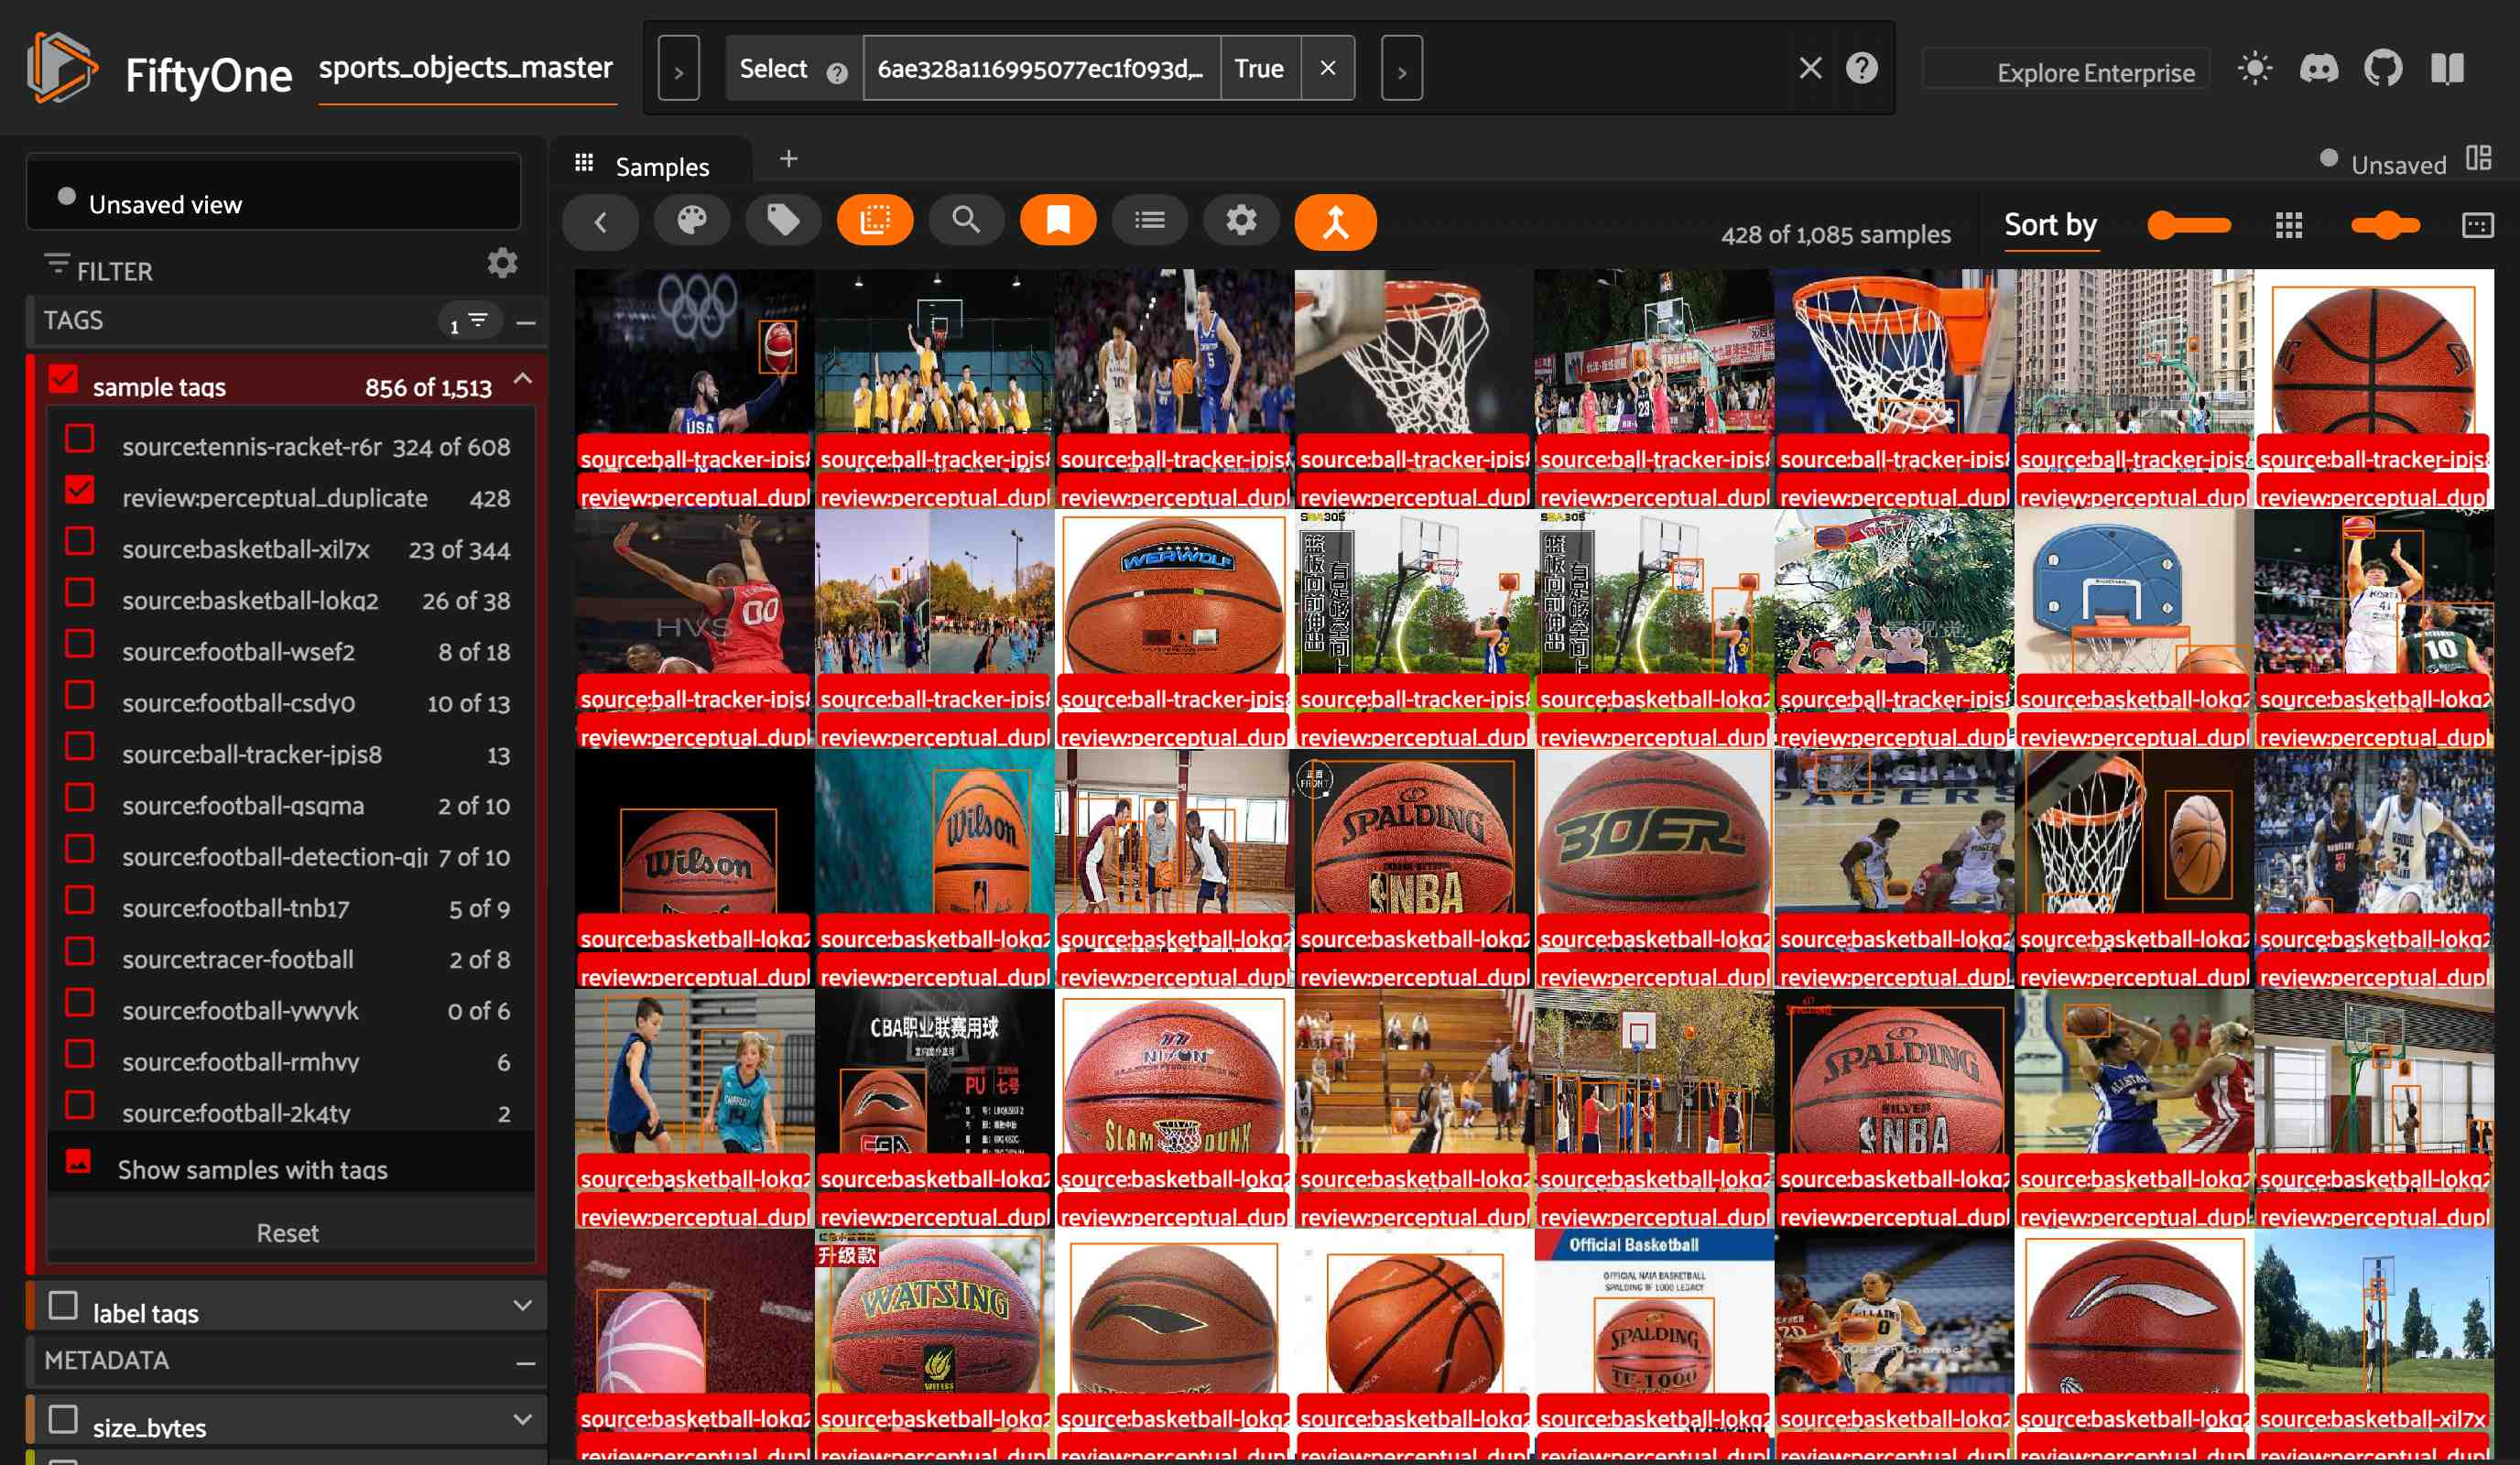

In [ ]:
perceptual_review_ids = list(
    dict.fromkeys(
        candidate_pairs[["sample_id_a", "sample_id_b"]].to_numpy().ravel()
    )
)
perceptual_review_view = master.select(perceptual_review_ids, ordered=True)

print(
    f"Manual review distances: ({PHASH_REVIEW_MIN_DISTANCE}, "
    f"{PHASH_REVIEW_MAX_DISTANCE}]"
)
print("Candidate pairs:", len(candidate_pairs))
print("Unique images in candidate pairs:", len(perceptual_review_ids))

if perceptual_review_ids:
    session = fo.launch_app(view=perceptual_review_view)
else:
    print("No candidate images to review in this distance range.")

In [ ]:
session.freeze()

### 3.7 Iteratively review candidate groups

Run this setup cell once to start or restart the review queue. Rerun it after
changing the review range and rebuilding `candidate_pairs`. The next cell uses the
App session opened by the overview above.

Images connected by candidate pairs form one review group. A-B and B-C put
A, B, and C together even when A-C falls outside the review range. Inspect groups
visually. Groups with lower maximum matched-pair distance appear first.

In [172]:
perceptual_neighbors = defaultdict(dict)
for pair in candidate_pairs.itertuples(index=False):
    perceptual_neighbors[pair.sample_id_a][pair.sample_id_b] = pair.hamming_distance
    perceptual_neighbors[pair.sample_id_b][pair.sample_id_a] = pair.hamming_distance

unvisited_ids = set(perceptual_neighbors)
group_rows = []
for seed_id in sorted(perceptual_neighbors):
    if seed_id not in unvisited_ids:
        continue

    pending_ids = [seed_id]
    unvisited_ids.remove(seed_id)
    group_ids = []
    while pending_ids:
        sample_id = pending_ids.pop()
        group_ids.append(sample_id)
        new_ids = set(perceptual_neighbors[sample_id]) & unvisited_ids
        unvisited_ids.difference_update(new_ids)
        pending_ids.extend(new_ids)

    # Each matched pair occurs twice in the undirected neighbor map.
    matched_distances = [
        distance
        for sample_id in group_ids
        for distance in perceptual_neighbors[sample_id].values()
    ]
    group_rows.append(
        {
            "sample_ids": sorted(group_ids),
            "image_count": len(group_ids),
            "candidate_pair_count": len(matched_distances) // 2,
            "min_distance": min(matched_distances),
            "max_distance": max(matched_distances),
        }
    )

perceptual_groups_to_review = pd.DataFrame(
    group_rows,
    columns=[
        "sample_ids", "image_count", "candidate_pair_count",
        "min_distance", "max_distance",
    ],
).sort_values(
    ["max_distance", "min_distance"], kind="stable"
).reset_index(drop=True)
perceptual_group_iterator = enumerate(
    perceptual_groups_to_review.itertuples(index=False), start=1
)
print("Candidate groups queued:", len(perceptual_groups_to_review))
print("Images queued:", int(perceptual_groups_to_review["image_count"].sum()))

Candidate groups queued: 444
Images queued: 1085


Rerun the following cell to show the next group. Each image appears in one
review group. The distance range describes matched pairs, rather than every
possible pair within the group. Review progress stays in memory until the
setup cell is rerun or the kernel restarts.
Apply sample tags such as `decision:keep`, `decision:duplicate`, or
`decision:uncertain` before advancing; selecting a thumbnail alone is temporary.

In [203]:
review_item = next(perceptual_group_iterator, None)
if review_item is None:
    print("No more candidate groups. Rerun the setup cell to restart the review.")
else:
    group_number, group = review_item
    perceptual_group_view = master.select(group.sample_ids, ordered=True)
    print(f"Group {group_number}/{len(perceptual_groups_to_review)}")
    print("Images:", group.image_count)
    print("Candidate pairs within group:", group.candidate_pair_count)
    print("Matched-pair distance range:", group.min_distance, "to", group.max_distance)
    session.view = perceptual_group_view

Group 31/444
Images: 2
Candidate pairs within group: 1
Matched-pair distance range: 6 to 6


### 3.8 Summarize duplicate tags

Count sample tags matching `review:*duplicate`. The total counts each sample
once even when it has multiple matching tags. This summary does not change tags.

In [204]:
from fnmatch import fnmatchcase

import pandas as pd

duplicate_review_tag_counts = {
    tag: count
    for tag, count in master.count_sample_tags().items()
    if fnmatchcase(tag, "review:*duplicate")
}
duplicate_tag_summary = pd.DataFrame(
    sorted(duplicate_review_tag_counts.items()), columns=["tag", "samples"]
)
display(duplicate_tag_summary)

duplicate_sample_count = (
    master.match_tags(list(duplicate_review_tag_counts)).count()
    if duplicate_review_tag_counts else 0
)
total_sample_count = master.count()
duplicate_sample_percent = (
    100 * duplicate_sample_count / total_sample_count if total_sample_count else 0
)
print(
    f"Unique duplicate-tagged samples: {duplicate_sample_count:,} / "
    f"{total_sample_count:,} ({duplicate_sample_percent:.2f}%)"
)
print("Samples without matching tags:", total_sample_count - duplicate_sample_count)

,tag,samples
0,review:exact_duplicate,389
1,review:perceptual_duplicate,4672


Unique duplicate-tagged samples: 5,061 / 34,003 (14.88%)
Samples without matching tags: 28942


In [205]:
session.show()

## 4. Detecting near duplicates (embedding similarity)